<a href="https://colab.research.google.com/github/Imanita7/AI-for-Science-and-Engineering/blob/main/Student_performance_statistics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Statistical Analysis of student performance
##The Objective
The objective is to explore the student performance dataset, imported in last week's assignment, using descriptive statistics and investigate the relationship between students' study time and their final academic grades.

This analysis will calculate the mean, median, range, variance and standard deviation for the selected numerical variables. It aims to also examine covariance and correlation between study time and final grades as well as visualize their relationship and express the relationship using a simple mathematical model.

In [9]:
!pip install -q ucimlrepo

from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#Importing the student performance dataset
student_performance = fetch_ucirepo(id = 320)
x_data = student_performance.data.features
y_data = student_performance.data.targets

#Combining targetcolumns and features
df = pd.concat([x_data, y_data], axis = 1)

#Displaying the first 5 rows
display(df.head())


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [10]:
#This is to inspect the numerical columns
print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

print("\nNumerical columns:")
print(df.select_dtypes(include = "number").columns.tolist())


Dataset shape: (649, 33)

Available columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Numerical columns:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


##Selecting of the Numerical Variables
The numerical variables selected for this analysis are:

    - Study time (studytime)
    - Absences (absences)
    - Previous-period grade (G2)
    - Final grade (G3)

These variables aid in explaining the students' study habits, attendance and academic performance. The analysis will examine their distributions and investigate the relationship between previous-period grades and final grades.

In [11]:
#The four selected numerical variables
selected_variables = ["studytime", "absences", "G2", "G3"]

#Calculating the descriptive statistics
statistics = pd.DataFrame(index = [
    "Mean",
    "Median",
    "Range",
    "Variance",
    "Standard Deviation"
])

for variable in selected_variables :
  data = df[variable].dropna()

  statistics[variable] = [
      data.mean(),
      data.median(),
      data.max() - data.min(),
      data.var(),
      data.std()
  ]

display(statistics.round(3))

,studytime,absences,G2,G3
Mean,1.931,3.659,11.570,11.906
Median,2.000,2.000,11.000,12.000
Range,3.000,32.000,19.000,19.000
Variance,0.688,21.537,8.489,10.437
Standard Deviation,0.830,4.641,2.914,3.231


In [12]:
g2 = df["G2"]
g3 = df["G3"]

#Calculating covariance and correlation
covariance = g2.cov(g3)
correlation = g2.corr(g3)

print("Covariance between G2 and G3:", round(covariance,3))
print("Correlation between G2 and G3:", round(correlation, 3))

Covariance between G2 and G3: 8.646
Correlation between G2 and G3: 0.919


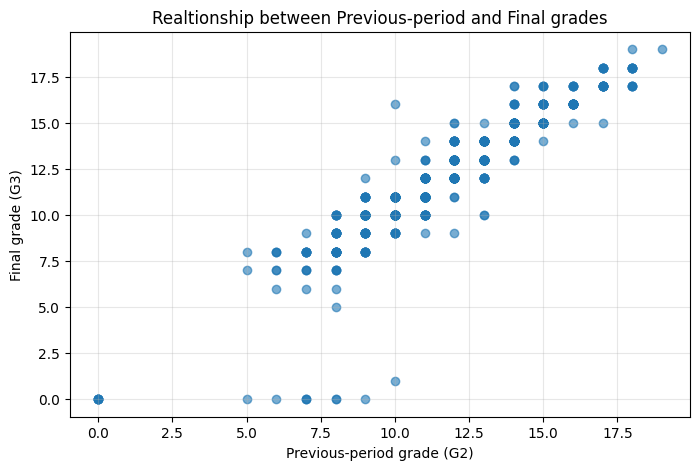

In [13]:
#Removing rows with null or missing values in either variable
plot_data = df[["G2", "G3"]].dropna()

#Creating the scatterplot
plt.figure(figsize = (8,5))
plt.scatter(plot_data["G2"], plot_data["G3"], alpha = 0.6)

plt.title("Realtionship between Previous-period and Final grades")
plt.xlabel("Previous-period grade (G2)")
plt.ylabel("Final grade (G3)")
plt.grid(True, alpha = 0.3)

plt.show()

##Interpretation of results
###What does the statistics tell us about the data?
The mean and median describe the central values of the selected variables and comparing them helps us understand the distribution of the data. The range shows the difference between the highest and the lowest observations while the variance and standard deviation indicate how widely the observations are spread out.

###What does the correlation tell us?
The correlation coefficient between G2 and G3 indicates the direction and strength of the linear relationship between previous-period grades and final grades. The correlation coefficient in the above dataset is 8.646 and since   its positive it indicates that higher previous-period grades tend to be associated with higher final grades.

###Does correlation mean causation?
No it does not. Correlation doesn't necessarily mean that one variable causes the other. Although previous-period and final grades are strongly related, since their correlation coefficient is close to positive one, other factors such as study habits, attendance and learning support may also influence academic performance.

In [14]:
#Rows with valid G2 and G3 values
model_data = df[["G2", "G3"]].dropna()

#Fit a simple linear model
b, a = np.polyfit(model_data["G2"], model_data["G3"], 1)
#Where b is the slope and a the intercept

print(f"Input: G2 (previous-period grade)")
print(f"Output: Predicted final grade")
print(f"Intercept (a): {a:.3f}")
print(f"Slope (b): {b:.3f}")

print(f"\nMathematical Model: G3_hat = {a:.3f} + ({b:.3f} * G2)")

Input: G2 (previous-period grade)
Output: Predicted final grade
Intercept (a): 0.122
Slope (b): 1.018

Mathematical Model: G3_hat = 0.122 + (1.018 * G2)


##Mathematical Model
The input-output relationship can be represented as:

  Input -> Function/Model -> Output

  Previous-period grade(G2) -> Linear Model -> Predicted final grade (G3)

The model is expressed as:

  $$
  \hat{G3} = a + bG2
  $$

The coefficients (a) and (b) are estimated from the data set using linear regression where (a) represents the intercept and (b) the slope. This model illustrates how a previous-period's grade can be used to estimate a students' final grade.

This is a simple statistical model for exploring the relationship between two variables. Its predictions would need to be evaluated before being used in practice.